> ⚡ **GPU version** of [9_interpolation_with_a_trend.ipynb](9_interpolation_with_a_trend.ipynb). Only the kriging and simulation calls change: they run
> through `gstatsim_gpu` with `backend=BACKEND` and are timed with `%%time`. Text, data, seeds and
> plots are the original demo's, so the results match it (to rounding).
>
> Needs an NVIDIA GPU and `pip install gstatsim[gpu]`. Without a GPU, `BACKEND` is set to `"cpu"`,
> which runs GStatSim itself.

In [1]:
# GPU version: use the GPU if there is one; otherwise "cpu" runs GStatSim itself
import gstatsim_gpu as gsg

BACKEND = "gpu" if gsg.gpu_status().available else "cpu"
print("Backend:", BACKEND, "|", gsg.gpu_status().device_name or gsg.gpu_status().reason)

C:\Users\alexi\miniforge3\envs\gstatsim-gpu\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Backend: gpu | NVIDIA GeForce RTX 5060 Laptop GPU


# Interpolation with a trend

Geologic phenomena often have large-scale trends that override small-scale variability. As such, trends can make it difficult to model the variograms. As such, it is sometimes helpful to detrend the data prior to interpolation. The interpolation is then performed on the detrended data, and the interpolated result is added back to the trend.

:::{figure-md} markdown-fig
<img src="https://github.com/GatorGlaciology/GStatSim/raw/main/images/detrending_schematic-01.jpg" class="bg-primary mb-1" width="800px">

Detrending
:::

Linear and polynomial trends are often used. However, we believe that non-parametric approaches are more versatile, especially for complex examples. Here we show how to use radial basis functions (RBFs) to estimate the trend. We uses this to perform kriging and SGS with a trend.

In [2]:
# load dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
from sklearn.preprocessing import QuantileTransformer 
import gstatsim as gs
import skgstat as skg
from skgstat import models
import random

## Load and plot data

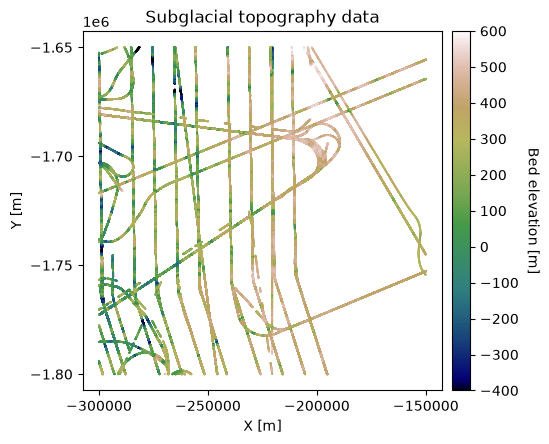

In [3]:
df_bed = pd.read_csv('data/greenland_test_data.csv') # download data
df_bed = df_bed[df_bed["Bed"] <= 700]  # remove erroneously high values, presumably due to bad bed picks

# plot data
fig = plt.figure(figsize = (5,5))
ax = plt.gca()
im = ax.scatter(df_bed['X'], df_bed['Y'], c=df_bed['Bed'], vmin=-400, vmax=600, 
                     marker='.', s=0.5, cmap='gist_earth')
plt.title('Subglacial topography data')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.locator_params(nbins=5)
plt.axis('scaled')

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
plt.show()

## Grid data

In [4]:
# Grid data
res = 1000  # resolution
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df_bed, 'X', 'Y', 'Bed', res) # grid data
df_grid = df_grid[df_grid["Z"].isnull() == False]  # remove coordinates with NaNs
df_grid = df_grid.rename(columns = {"Z": "Bed"}) # rename column for consistency

## Compute trend

In [5]:
smooth_radius = 100000 # smoothing radius for RBF function (100 km)
trend_rbf = gs.rbf_trend(grid_matrix, smooth_radius, res)

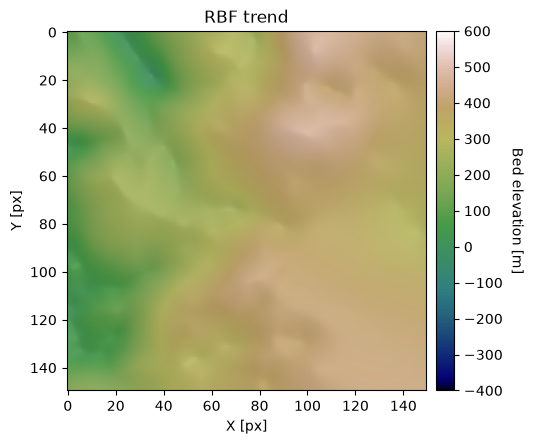

In [6]:
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)

# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(trend_rbf, vert_exag=1, dx=1, dy=1, fraction=1.0)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(trend_rbf, vmin=-400, vmax=600, cmap='gist_earth')
ax.imshow(hillshade, cmap='gray', alpha=0.1)
ax.set_title('RBF trend')
ax.set_xlabel('X [px]'); ax.set_ylabel('Y [px]')
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

## Compute residual from trend

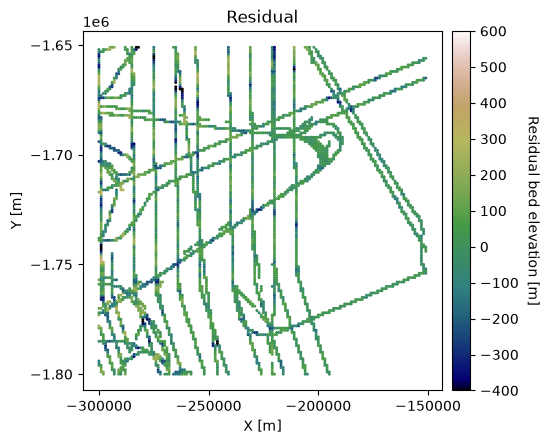

In [7]:
# subtract trend from data
diff = grid_matrix - trend_rbf
diff = np.flipud(diff) # flip matrix

# remove NaNs, add to dataframe
ny, nx = diff.shape
diff_array = np.reshape(diff,[ny*nx])
diff_array = diff_array[~np.isnan(diff_array)]
df_grid['Residual'] = diff_array

# plot residual 
fig = plt.figure(figsize = (5,5))
ax = plt.gca()
im = ax.scatter(df_grid['X'], df_grid['Y'], c=df_grid['Residual'], vmin=-400, vmax=600, 
                     marker='.', s=5, cmap='gist_earth')
plt.title('Residual')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.locator_params(nbins=5)
plt.axis('scaled')

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Residual bed elevation [m]", rotation=270, labelpad=15)
plt.show()

## Normal score transformation for residual data

In [8]:
data = df_grid['Residual'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data)
df_grid['Nres'] = nst_trans.transform(data) 

## Variogram analysis for residual data

In [9]:
# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nres']

maxlag = 50000 # maximum range distance
n_lags = 70 #num of bins

V1 = skg.Variogram(coords, values, bin_func = "even", n_lags = n_lags, 
                   maxlag = maxlag, normalize=False)

# extract variogram values
xdata = V1.bins
ydata = V1.experimental

V1.model = 'exponential' # use exponential variogram model

In [10]:
# set variogram parameters
vrange = V1.parameters[0]
vsill = V1.parameters[1]
vnugget = V1.parameters[2]

# evaluate models
xi =np.linspace(0, xdata[-1], 1000) 
y_exp = [models.exponential(h, vrange, vsill, vnugget) for h in xi]

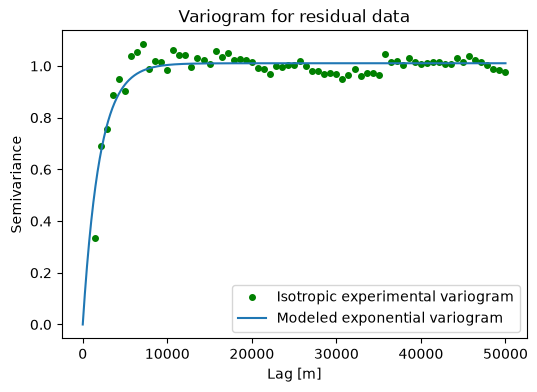

In [11]:
# plot variogram model
plt.figure(figsize=(6,4))
plt.plot(xdata, ydata, 'og', markersize=4, label='Isotropic experimental variogram')
plt.plot(xi, y_exp, '-', markersize=4, label='Modeled exponential variogram')
plt.title('Variogram for residual data')
plt.xlabel('Lag [m]'); plt.ylabel('Semivariance')  
plt.legend(loc='lower right')
plt.show()

The variogram sill here reaches 1, which makes sense because the variance of data with a standard Gaussian distribution should in theory be 1. In contrast, the variogram for the non-detrended data in Tutorial 2 (2_Variogram_model.ipynb) did not have a variogram of 1, which is a less desirable condition. As such, using the residual can lead to better variogram modeling, which makes the interpolation functions more effective.

## Initialize grid

Make list of grid cells that need to be simulated.

In [12]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

## Kriging with a trend

Here will apply a kriging interpolation to the residual and add it to the trend. This procedure is known as kriging with a trend or universal kriging. Note that simple kriging should be used to krige the residual because the detrended data set has a constant mean.

In [13]:
%%time
# set variogram parameters
azimuth = 0
nugget = V1.parameters[2]

# the major and minor ranges are the same in this example because it is isotropic
major_range = V1.parameters[0]
minor_range = V1.parameters[0]
sill = V1.parameters[1]
vtype = 'Exponential'
vario = [azimuth, nugget, major_range, minor_range, sill, vtype]

k = 100           # number of neighboring data points used to estimate a given point 
rad = 50000       # 50 km search radius

# est_SK is the estimate and var_SK is the variance
est_SK, var_SK = gsg.predict(df_grid, Pred_grid_xy, vario, num_points=k, radius=rad, method='simple', xx='X', yy='Y', zz='Nres', backend=BACKEND) 

CPU times: total: 4.59 s
Wall time: 6.18 s


In [14]:
# reverse normal score transformation
est = est_SK.reshape(-1,1)
spred_trans = nst_trans.inverse_transform(est)

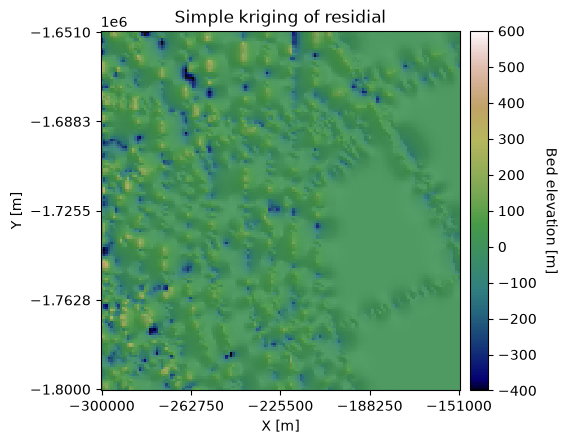

In [15]:
# make hillshade for visualizing
vmin = -400; vmax = 600
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = spred_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Simple kriging of residial')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

Now let's add the trend:

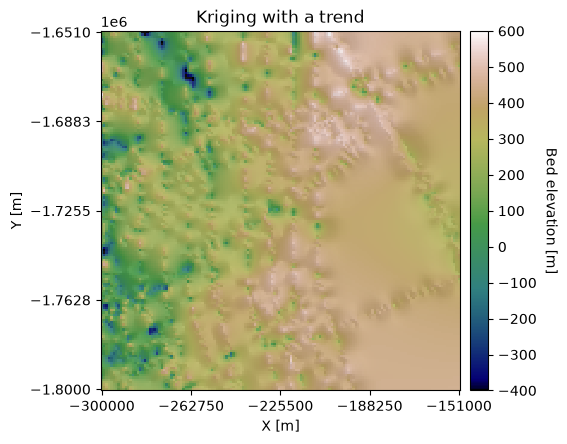

In [16]:
# add trend to kriging result
sk_total = mat + trend_rbf
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, sk_total, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Kriging with a trend')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

## Sequential Gaussian simulation

Now we will apply SGS to the residual. We will use the version of SGS that uses simple kriging.

In [17]:
%%time
rng = np.random.default_rng(seed=0)
sim = gsg.sgs(df_grid, Pred_grid_xy, vario, num_points=k, radius=rad, method='simple', xx='X', yy='Y', zz='Nres', seed=rng, backend=BACKEND) 

CPU times: total: 13.1 s
Wall time: 14.4 s


In [18]:
# reverse normal score transformation
sim1 = sim.reshape(-1,1)
sim_trans = nst_trans.inverse_transform(sim1)

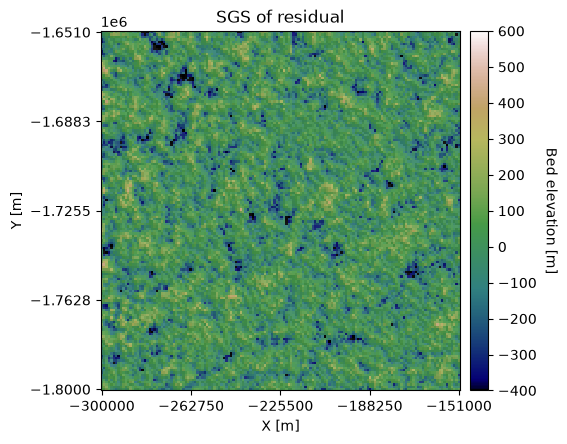

In [19]:
# make hillshade for visualizing
mat = sim_trans.reshape((rows, cols))

cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('SGS of residual')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

Now let's add the trend:

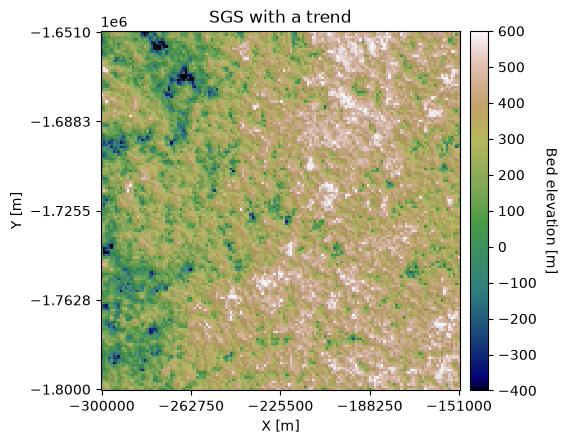

In [20]:
# add trend
sgs_total = mat + trend_rbf

# make hillshade for visualizing
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, sgs_total, vmin=vmin, vmax=vmax, cmap=cmap)
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('SGS with a trend')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

## Variogram analysis

Let's compare the variograms of the residual data and the SGS residual to assess simulation performance.

In [21]:
# compute SGS variogram
# downsample random indices to speed this up
rand_indices = rng.choice(range(np.shape(Pred_grid_xy)[0]),5000)

# coordinates and values of simulated topography prior to back transormation
coords_s = Pred_grid_xy[rand_indices]
values_s = sim[rand_indices]

VS = skg.Variogram(coords_s, values_s, bin_func = "even", n_lags = n_lags, 
                   maxlag = maxlag, normalize=False)

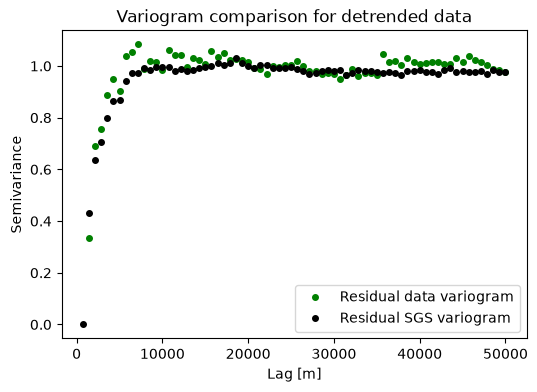

In [22]:
# plot variogram

# extract variogram values

# experimental variogram (from beginning of script)
xe = V1.bins
ye = V1.experimental

# simple kriging variogram
xs = VS.bins
ys = VS.experimental

plt.figure(figsize=(6,4))
plt.plot(xe, ye, 'og', markersize=4, label='Residual data variogram')
plt.plot(xs, ys, 'ok', markersize=4, label='Residual SGS variogram')
plt.title('Variogram comparison for detrended data')
plt.xlabel('Lag [m]'); plt.ylabel('Semivariance')
plt.legend(loc='lower right')
plt.show()

Compared to the Sequential Gaussian Simulation demo, the variograms have better agreement.

Download the tutorial {Download}`here<./9_interpolation_with_a_trend.ipynb>`.